In [10]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [11]:
import os

path = "/content/drive/MyDrive"

print("Files and folders in My Drive:")

for item in os.listdir(path):
    print(item)

Files and folders in My Drive:
plantvillage dataset.zip
Colab Notebooks
Plant_Disease_Project
t10k-images.idx3-ubyte
t10k-labels.idx1-ubyte
train-images.idx3-ubyte
train-labels.idx1-ubyte


In [12]:
import os

base_path = "/content/drive/MyDrive"

for root, dirs, files in os.walk(base_path):
    if "train-images.idx3-ubyte" in files:
        path = root
        break

print("Dataset location:", path)
print("Dataset files:")

for file in os.listdir(path):
    print(file)

Dataset location: /content/drive/MyDrive
Dataset files:
plantvillage dataset.zip
Colab Notebooks
Plant_Disease_Project
t10k-images.idx3-ubyte
t10k-labels.idx1-ubyte
train-images.idx3-ubyte
train-labels.idx1-ubyte


In [13]:
import numpy as np
import struct
import os

def load_images(filename):
    with open(filename, 'rb') as f:
        magic, num, rows, cols = struct.unpack(">IIII", f.read(16))
        images = np.frombuffer(f.read(), dtype=np.uint8)
        return images.reshape(num, rows, cols)

def load_labels(filename):
    with open(filename, 'rb') as f:
        magic, num = struct.unpack(">II", f.read(8))
        labels = np.frombuffer(f.read(), dtype=np.uint8)
        return labels

x_train = load_images(os.path.join(path, "train-images.idx3-ubyte"))
y_train = load_labels(os.path.join(path, "train-labels.idx1-ubyte"))

x_test = load_images(os.path.join(path, "t10k-images.idx3-ubyte"))
y_test = load_labels(os.path.join(path, "t10k-labels.idx1-ubyte"))

print("Training images:", x_train.shape)
print("Training labels:", y_train.shape)
print("Testing images:", x_test.shape)
print("Testing labels:", y_test.shape)

Training images: (60000, 28, 28)
Training labels: (60000,)
Testing images: (10000, 28, 28)
Testing labels: (10000,)


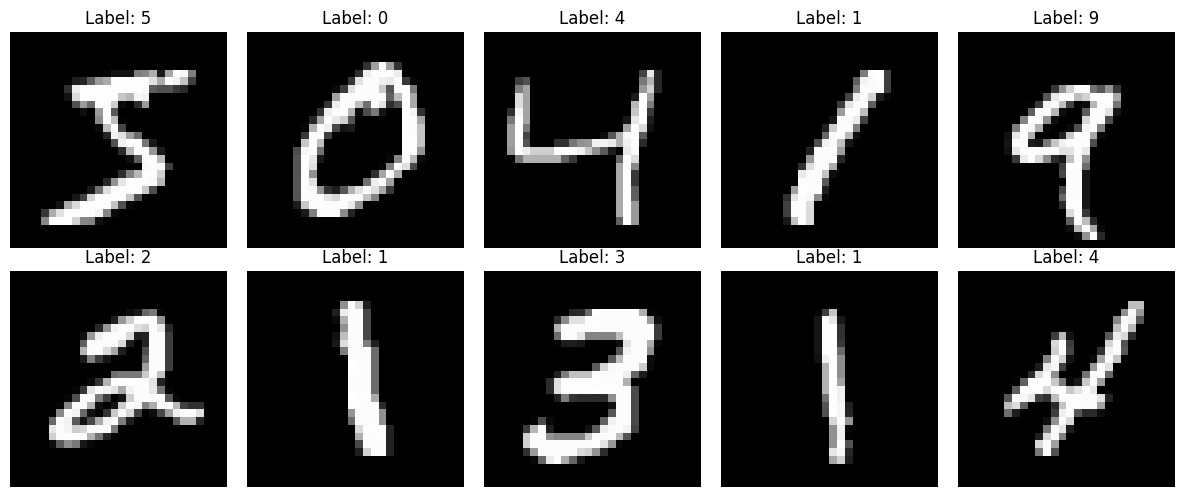

In [14]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)

    plt.imshow(x_train[i], cmap='gray')

    plt.title(f"Label: {y_train[i]}")

    plt.axis('off')

plt.tight_layout()
plt.show()

In [15]:
print("Image shape:", x_train[0].shape)
print("Label:", y_train[0])
print("Pixel values:", x_train[0].min(), "to", x_train[0].max())

Image shape: (28, 28)
Label: 5
Pixel values: 0 to 255


In [16]:
# Normalize pixel values
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

print("Minimum pixel value:", x_train.min())
print("Maximum pixel value:", x_train.max())

Minimum pixel value: 0.0
Maximum pixel value: 1.0


In [17]:
x_train_ann = x_train.reshape(60000, 784)
x_test_ann = x_test.reshape(10000, 784)

print("ANN Training shape:", x_train_ann.shape)
print("ANN Testing shape:", x_test_ann.shape)

ANN Training shape: (60000, 784)
ANN Testing shape: (10000, 784)


In [18]:
x_train_cnn = x_train.reshape(60000, 28, 28, 1)
x_test_cnn = x_test.reshape(10000, 28, 28, 1)

print("CNN Training shape:", x_train_cnn.shape)
print("CNN Testing shape:", x_test_cnn.shape)

CNN Training shape: (60000, 28, 28, 1)
CNN Testing shape: (10000, 28, 28, 1)


In [19]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten

In [20]:
ann_model = Sequential([
    Dense(128, activation='relu', input_shape=(784,)),

    Dense(64, activation='relu'),

    Dense(10, activation='softmax')
])

ann_model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

In [21]:
ann_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [22]:
ann_history = ann_model.fit(
    x_train_ann,
    y_train,
    epochs=10,
    batch_size=32,
    validation_split=0.1
)

Epoch 1/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 10s 4ms/step - accuracy: 0.9231 - loss: 0.2589 - val_accuracy: 0.9672 - val_loss: 0.1172
Epoch 2/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9667 - loss: 0.1091 - val_accuracy: 0.9678 - val_loss: 0.1095
Epoch 3/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9761 - loss: 0.0750 - val_accuracy: 0.9713 - val_loss: 0.0947
Epoch 4/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9822 - loss: 0.0550 - val_accuracy: 0.9790 - val_loss: 0.0776
Epoch 5/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9856 - loss: 0.0435 - val_accuracy: 0.9770 - val_loss: 0.0839
Epoch 6/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9878 - loss: 0.0370 - val_accuracy: 0.9738 - val_loss: 0.0935
Epoch 7/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9906 - loss: 0.0284 - val_accuracy: 0.9778 - val_loss: 0.0939
Epoch 8/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9913 - loss: 0.0251 -

In [23]:
ann_loss, ann_accuracy = ann_model.evaluate(
    x_test_ann,
    y_test
)

print("ANN Test Accuracy:", ann_accuracy * 100, "%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9765 - loss: 0.0930
ANN Test Accuracy: 97.64999747276306 %


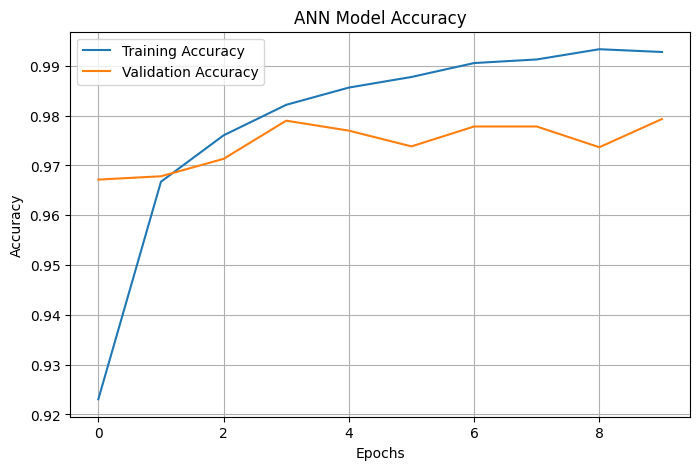

In [24]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.plot(ann_history.history['accuracy'], label='Training Accuracy')
plt.plot(ann_history.history['val_accuracy'], label='Validation Accuracy')

plt.title('ANN Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid()

plt.show()

In [25]:
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Conv2D,
    MaxPooling2D,
    Flatten,
    Dense,
    Dropout
)

In [26]:
cnn_model = Sequential([

    # First convolution layer
    Conv2D(32, (3,3), activation='relu',
           input_shape=(28,28,1)),

    # First pooling layer
    MaxPooling2D((2,2)),

    # Second convolution layer
    Conv2D(64, (3,3), activation='relu'),

    # Second pooling layer
    MaxPooling2D((2,2)),

    # Convert feature maps into 1D
    Flatten(),

    # Fully connected layer
    Dense(128, activation='relu'),

    Dropout(0.3),

    # Output layer
    Dense(10, activation='softmax')
])

cnn_model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

In [27]:
cnn_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [28]:
cnn_history = cnn_model.fit(
    x_train_cnn,
    y_train,
    epochs=10,
    batch_size=32,
    validation_split=0.1
)

Epoch 1/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 20s 8ms/step - accuracy: 0.9478 - loss: 0.1692 - val_accuracy: 0.9837 - val_loss: 0.0517
Epoch 2/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9820 - loss: 0.0574 - val_accuracy: 0.9898 - val_loss: 0.0361
Epoch 3/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9876 - loss: 0.0415 - val_accuracy: 0.9908 - val_loss: 0.0370
Epoch 4/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9898 - loss: 0.0331 - val_accuracy: 0.9897 - val_loss: 0.0388
Epoch 5/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9926 - loss: 0.0243 - val_accuracy: 0.9903 - val_loss: 0.0365
Epoch 6/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9931 - loss: 0.0209 - val_accuracy: 0.9927 - val_loss: 0.0325
Epoch 7/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9946 - loss: 0.0174 - val_accuracy: 0.9925 - val_loss: 0.0340
Epoch 8/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9947 - loss: 0.0158 -

In [29]:
cnn_loss, cnn_accuracy = cnn_model.evaluate(
    x_test_cnn,
    y_test
)

print("CNN Test Accuracy:", cnn_accuracy * 100, "%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9925 - loss: 0.0257
CNN Test Accuracy: 99.25000071525574 %


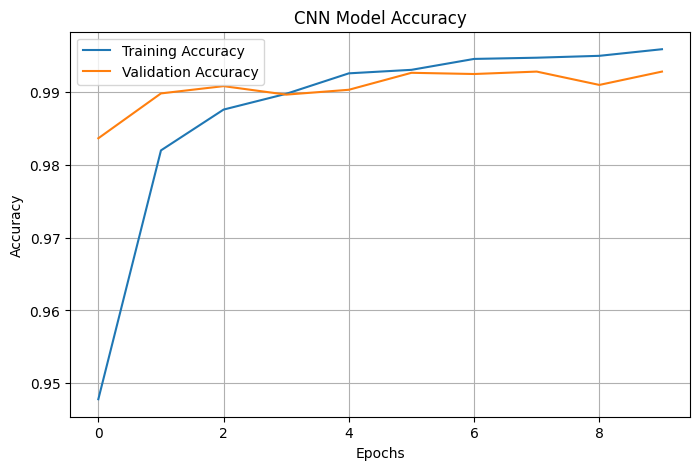

In [30]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.plot(cnn_history.history['accuracy'],
         label='Training Accuracy')

plt.plot(cnn_history.history['val_accuracy'],
         label='Validation Accuracy')

plt.title('CNN Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')

plt.legend()
plt.grid()
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step


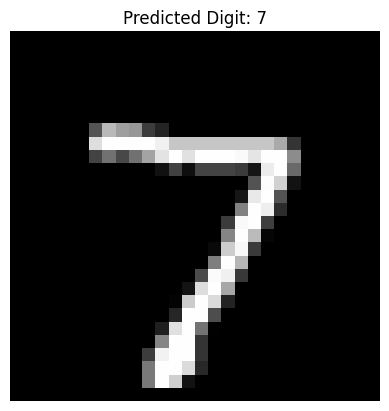

Actual Digit: 7
Predicted Digit: 7


In [31]:
import numpy as np
import matplotlib.pyplot as plt

prediction = cnn_model.predict(x_test_cnn[0:1])

predicted_digit = np.argmax(prediction)

plt.imshow(x_test[0], cmap='gray')
plt.title(f"Predicted Digit: {predicted_digit}")
plt.axis('off')
plt.show()

print("Actual Digit:", y_test[0])
print("Predicted Digit:", predicted_digit)

In [32]:
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Conv2D,
    AveragePooling2D,
    Flatten,
    Dense
)

In [33]:
lenet_model = Sequential([

    # Input and first convolution
    Conv2D(6, (5,5), activation='tanh',
           padding='same', input_shape=(28,28,1)),

    # First average pooling
    AveragePooling2D((2,2)),

    # Second convolution
    Conv2D(16, (5,5), activation='tanh'),

    # Second average pooling
    AveragePooling2D((2,2)),

    # Flatten layer
    Flatten(),

    # Fully connected layers
    Dense(120, activation='tanh'),

    Dense(84, activation='tanh'),

    # Output layer
    Dense(10, activation='softmax')
])

lenet_model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 6)      │           156 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d               │ (None, 14, 14, 6)      │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 10, 10, 16)     │         2,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_1             │ (None, 5, 5, 16)       │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 400)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 120)            │        48,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 84)             │        10,164 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 10)             │           850 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 61,706 (241.04 KB)

 Trainable params: 61,706 (241.04 KB)

 Non-trainable params: 0 (0.00 B)

In [34]:
lenet_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [35]:
lenet_history = lenet_model.fit(
    x_train_cnn,
    y_train,
    epochs=10,
    batch_size=32,
    validation_split=0.1
)

Epoch 1/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 16s 6ms/step - accuracy: 0.9272 - loss: 0.2465 - val_accuracy: 0.9745 - val_loss: 0.0948
Epoch 2/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 11s 3ms/step - accuracy: 0.9721 - loss: 0.0917 - val_accuracy: 0.9807 - val_loss: 0.0674
Epoch 3/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9811 - loss: 0.0623 - val_accuracy: 0.9812 - val_loss: 0.0638
Epoch 4/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9854 - loss: 0.0461 - val_accuracy: 0.9850 - val_loss: 0.0539
Epoch 5/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9883 - loss: 0.0372 - val_accuracy: 0.9827 - val_loss: 0.0619
Epoch 6/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9903 - loss: 0.0295 - val_accuracy: 0.9875 - val_loss: 0.0430
Epoch 7/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9916 - loss: 0.0254 - val_accuracy: 0.9853 - val_loss: 0.0595
Epoch 8/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9934 - loss: 0.0202 

In [36]:
lenet_loss, lenet_accuracy = lenet_model.evaluate(
    x_test_cnn,
    y_test
)

print("LeNet-5 Test Accuracy:",
      lenet_accuracy * 100, "%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9864 - loss: 0.0511
LeNet-5 Test Accuracy: 98.64000082015991 %


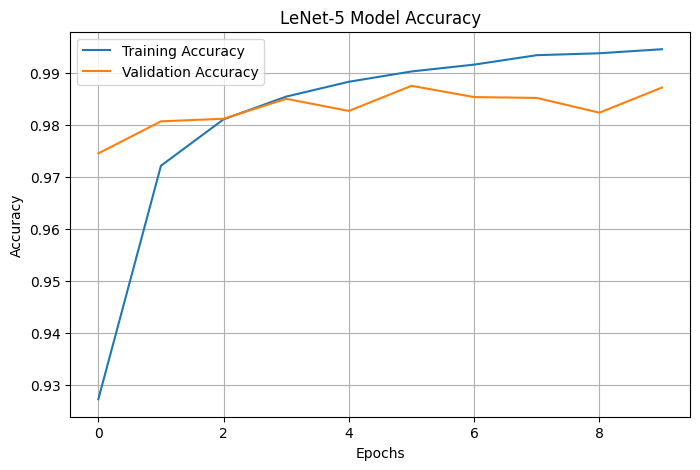

In [37]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.plot(lenet_history.history['accuracy'],
         label='Training Accuracy')

plt.plot(lenet_history.history['val_accuracy'],
         label='Validation Accuracy')

plt.title('LeNet-5 Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')

plt.legend()
plt.grid()
plt.show()

In [38]:
import pandas as pd

results = pd.DataFrame({
    'Model': ['ANN', 'CNN', 'LeNet-5'],
    'Test Accuracy': [
        ann_accuracy * 100,
        cnn_accuracy * 100,
        lenet_accuracy * 100
    ]
})

print(results)

     Model  Test Accuracy
0      ANN      97.649997
1      CNN      99.250001
2  LeNet-5      98.640001


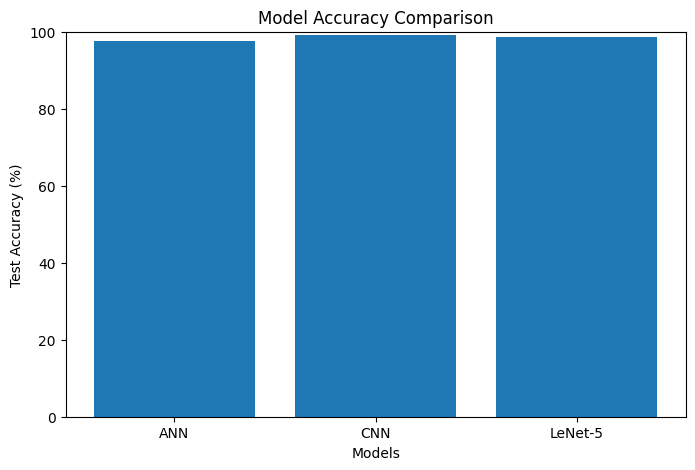

In [39]:
plt.figure(figsize=(8,5))

plt.bar(results['Model'], results['Test Accuracy'])

plt.title('Model Accuracy Comparison')
plt.xlabel('Models')
plt.ylabel('Test Accuracy (%)')

plt.ylim(0, 100)
plt.show()

In [40]:
import numpy as np

# ANN predictions
ann_predictions = ann_model.predict(x_test_ann)
ann_predicted = np.argmax(ann_predictions, axis=1)

# CNN predictions
cnn_predictions = cnn_model.predict(x_test_cnn)
cnn_predicted = np.argmax(cnn_predictions, axis=1)

# LeNet-5 predictions
lenet_predictions = lenet_model.predict(x_test_cnn)
lenet_predicted = np.argmax(lenet_predictions, axis=1)

print("All three models generated predictions successfully!")

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
All three models generated predictions successfully!


In [41]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import pandas as pd

models = {
    "ANN": ann_predicted,
    "CNN": cnn_predicted,
    "LeNet-5": lenet_predicted
}

results = []

for name, predictions in models.items():

    accuracy = accuracy_score(y_test, predictions)

    precision = precision_score(
        y_test, predictions, average='weighted'
    )

    recall = recall_score(
        y_test, predictions, average='weighted'
    )

    f1 = f1_score(
        y_test, predictions, average='weighted'
    )

    results.append([
        name,
        accuracy * 100,
        precision * 100,
        recall * 100,
        f1 * 100
    ])

evaluation_df = pd.DataFrame(
    results,
    columns=[
        "Model",
        "Accuracy (%)",
        "Precision (%)",
        "Recall (%)",
        "F1-Score (%)"
    ]
)

print(evaluation_df.round(2))

     Model  Accuracy (%)  Precision (%)  Recall (%)  F1-Score (%)
0      ANN         97.65          97.66       97.65         97.65
1      CNN         99.25          99.25       99.25         99.25
2  LeNet-5         98.64          98.64       98.64         98.64


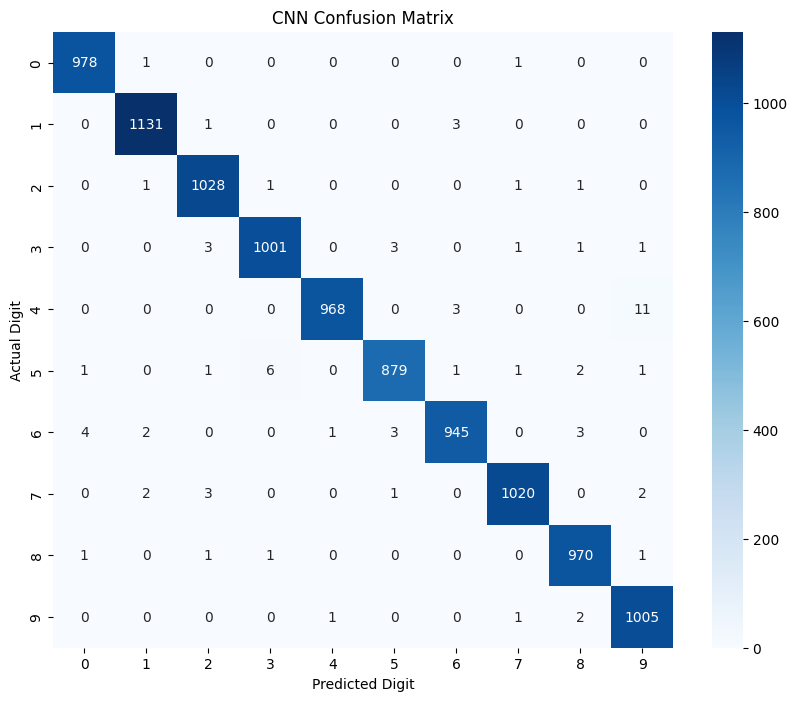

In [44]:
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, cnn_predicted)

plt.figure(figsize=(10,8))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.title("CNN Confusion Matrix")
plt.xlabel("Predicted Digit")
plt.ylabel("Actual Digit")

plt.show()

In [45]:
from sklearn.metrics import classification_report

print("CNN Classification Report")

print(
    classification_report(
        y_test,
        cnn_predicted
    )
)

CNN Classification Report
              precision    recall  f1-score   support

           0       0.99      1.00      1.00       980
           1       0.99      1.00      1.00      1135
           2       0.99      1.00      0.99      1032
           3       0.99      0.99      0.99      1010
           4       1.00      0.99      0.99       982
           5       0.99      0.99      0.99       892
           6       0.99      0.99      0.99       958
           7       1.00      0.99      0.99      1028
           8       0.99      1.00      0.99       974
           9       0.98      1.00      0.99      1009

    accuracy                           0.99     10000
   macro avg       0.99      0.99      0.99     10000
weighted avg       0.99      0.99      0.99     10000



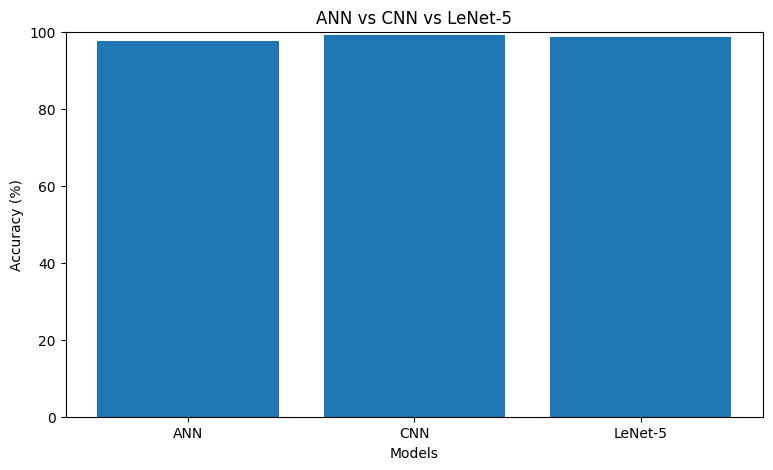

In [46]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9,5))

plt.bar(
    evaluation_df["Model"],
    evaluation_df["Accuracy (%)"]
)

plt.title("ANN vs CNN vs LeNet-5")
plt.xlabel("Models")
plt.ylabel("Accuracy (%)")

plt.ylim(0, 100)
plt.show()

In [47]:
!pip install gradio

In [48]:
import gradio as gr
import numpy as np
from PIL import Image

def predict_digit(image):

    image = image.convert("L")
    image = image.resize((28, 28))

    image = np.array(image)

    image = 255 - image

    image = image.astype("float32") / 255.0

    image = image.reshape(1, 28, 28, 1)

    prediction = cnn_model.predict(image, verbose=0)

    probabilities = prediction[0]

    return {
        str(i): float(probabilities[i])
        for i in range(10)
    }

demo = gr.Interface(
    fn=predict_digit,
    inputs=gr.Image(type="pil"),
    outputs=gr.Label(num_top_classes=10),
    title="Handwritten Digit Recognition",
    description="Upload a handwritten digit image from 0 to 9."
)

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://a73843d73e1e0b8da4.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [49]:
ann_model.save('/content/drive/MyDrive/ann_model.keras')

cnn_model.save('/content/drive/MyDrive/cnn_model.keras')

lenet_model.save('/content/drive/MyDrive/lenet_model.keras')

print("All models saved successfully!")

All models saved successfully!


In [50]:
import pandas as pd

results = pd.DataFrame({
    'Model': ['ANN', 'CNN', 'LeNet-5'],
    'Accuracy (%)': [
        ann_accuracy * 100,
        cnn_accuracy * 100,
        lenet_accuracy * 100
    ]
})

print(results.round(2))

     Model  Accuracy (%)
0      ANN         97.65
1      CNN         99.25
2  LeNet-5         98.64


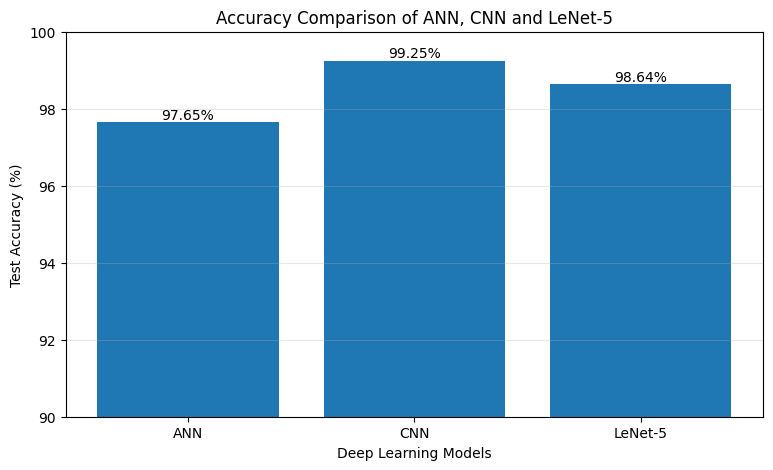

In [51]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9,5))

bars = plt.bar(
    results['Model'],
    results['Accuracy (%)']
)

plt.bar_label(bars, fmt='%.2f%%')

plt.title('Accuracy Comparison of ANN, CNN and LeNet-5')
plt.xlabel('Deep Learning Models')
plt.ylabel('Test Accuracy (%)')

plt.ylim(90, 100)
plt.grid(axis='y', alpha=0.3)

plt.show()

In [52]:
results.to_csv(
    '/content/drive/MyDrive/AIDL_Model_Results.csv',
    index=False
)

print("Results saved successfully!")

Results saved successfully!
